In [1]:
from pathlib import Path

print(Path.cwd())
print(Path("/home/y2a").exists())

/home/y2a
True


In [2]:
# ============================================================
# CELL 1 — UNZIP KAGGLE TEST IMAGES
# ============================================================

from pathlib import Path
import zipfile

ZIP_PATH = Path("/home/y2a/Kaggle (1).zip")
TASK8_DIR = Path("/home/y2a/task8_data")

print("Notebook working directory:", Path.cwd())
print("ZIP exists:", ZIP_PATH.exists())
print("ZIP path:", ZIP_PATH)

assert ZIP_PATH.exists(), f"ZIP not found: {ZIP_PATH}"

TASK8_DIR.mkdir(
    parents=True,
    exist_ok=True
)

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as z:
    z.extractall(TASK8_DIR)

TEST_IMAGE_DIR = TASK8_DIR / "Kaggle"

test_images = sorted(
    TEST_IMAGE_DIR.glob("*.png")
)

print()
print("Extracted to:", TASK8_DIR)
print("Test image directory:", TEST_IMAGE_DIR)
print("Images found:", len(test_images))

assert len(test_images) == 19, (
    f"Expected 19 Kaggle images, found {len(test_images)}"
)

for path in test_images:
    print(path.name)

Notebook working directory: /home/y2a
ZIP exists: True
ZIP path: /home/y2a/Kaggle (1).zip

Extracted to: /home/y2a/task8_data
Test image directory: /home/y2a/task8_data/Kaggle
Images found: 19
test_image_01.png
test_image_02.png
test_image_03.png
test_image_04.png
test_image_05.png
test_image_06.png
test_image_07.png
test_image_08.png
test_image_09.png
test_image_10.png
test_image_11.png
test_image_12.png
test_image_13.png
test_image_14.png
test_image_15.png
test_image_16.png
test_image_17.png
test_image_18.png
test_image_19.png


In [3]:
# ============================================================
# CELL 1 — PATHS + UNZIP KAGGLE TEST DATA
# ============================================================

from pathlib import Path
import zipfile

BASE_DIR = Path("/home/y2a")

KAGGLE_ZIP = BASE_DIR / "Kaggle (1).zip"
TASK8_DIR = BASE_DIR / "task8_pipeline"
DATA_DIR = TASK8_DIR / "data"
OUTPUT_DIR = TASK8_DIR / "outputs"

ROOT_MODEL_PATH = BASE_DIR / "NikaSoleimanzadeh_244258_unet_model_512px.h5"

assert KAGGLE_ZIP.exists(), f"Kaggle ZIP missing: {KAGGLE_ZIP}"
assert ROOT_MODEL_PATH.exists(), f"Root model missing: {ROOT_MODEL_PATH}"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(KAGGLE_ZIP, "r") as z:
    z.extractall(DATA_DIR)

TEST_IMAGE_DIR = DATA_DIR / "Kaggle"

test_images = sorted(TEST_IMAGE_DIR.glob("*.png"))

print("Kaggle ZIP:", KAGGLE_ZIP)
print("Root model:", ROOT_MODEL_PATH)
print("Test image directory:", TEST_IMAGE_DIR)
print("Number of test images:", len(test_images))

assert TEST_IMAGE_DIR.exists(), f"Image folder missing: {TEST_IMAGE_DIR}"
assert len(test_images) > 0, "No PNG test images found."

for p in test_images:
    print(p.name)

Kaggle ZIP: /home/y2a/Kaggle (1).zip
Root model: /home/y2a/NikaSoleimanzadeh_244258_unet_model_512px.h5
Test image directory: /home/y2a/task8_pipeline/data/Kaggle
Number of test images: 19
test_image_01.png
test_image_02.png
test_image_03.png
test_image_04.png
test_image_05.png
test_image_06.png
test_image_07.png
test_image_08.png
test_image_09.png
test_image_10.png
test_image_11.png
test_image_12.png
test_image_13.png
test_image_14.png
test_image_15.png
test_image_16.png
test_image_17.png
test_image_18.png
test_image_19.png


In [4]:
# ============================================================
# CELL 2 — LOAD TASK 5 ROOT SEGMENTATION MODEL
# ============================================================

import tensorflow as tf

custom_objects = {
    "RootSeg>GroupNormalization": tf.keras.layers.GroupNormalization,
    "GroupNormalization": tf.keras.layers.GroupNormalization,
}

root_model = tf.keras.models.load_model(
    ROOT_MODEL_PATH,
    custom_objects=custom_objects,
    compile=False
)

print("Model loaded successfully.")
print("Input shape :", root_model.input_shape)
print("Output shape:", root_model.output_shape)

assert root_model.input_shape[-3:] == (512, 512, 1), (
    f"Unexpected model input shape: {root_model.input_shape}"
)

I0000 00:00:1791209024.564376  953832 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791209024.614547  953832 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791209025.948080  953832 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1791209029.799462  953832 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FOR

Model loaded successfully.
Input shape : (None, 512, 512, 1)
Output shape: (None, 512, 512, 1)


test_image_01.png    4202 × 3006 channels=3
test_image_02.png    4202 × 3006 channels=3
test_image_03.png    4202 × 3006 channels=3
test_image_04.png    4202 × 3006 channels=3
test_image_05.png    4202 × 3006 channels=3
test_image_06.png    4202 × 3006 channels=3
test_image_07.png    4202 × 3006 channels=3
test_image_08.png    4202 × 3006 channels=3
test_image_09.png    4202 × 3006 channels=3
test_image_10.png    4202 × 3006 channels=3
test_image_11.png    4202 × 3006 channels=3
test_image_12.png    4202 × 2999 channels=3
test_image_13.png    4202 × 3006 channels=3
test_image_14.png    4202 × 3006 channels=3
test_image_15.png    4112 × 3006 channels=3
test_image_16.png    4202 × 3006 channels=3
test_image_17.png    4202 × 3006 channels=3
test_image_18.png    4202 × 3006 channels=3
test_image_19.png    4202 × 3006 channels=3


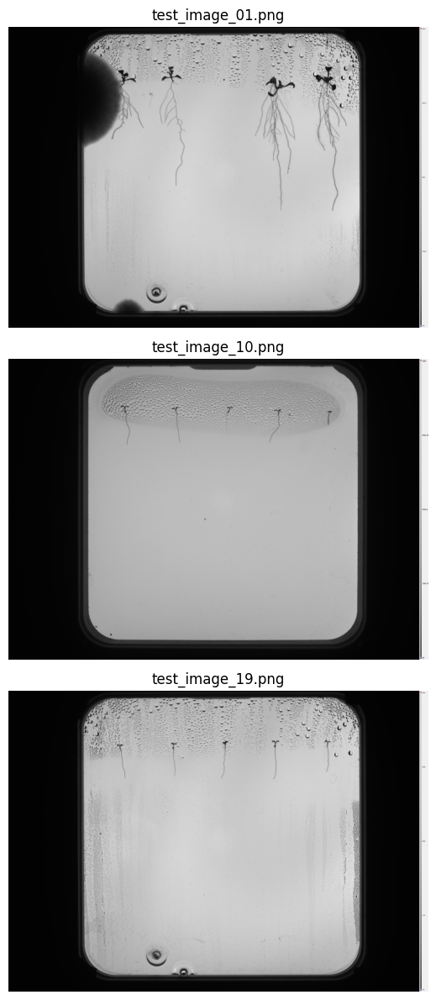

In [5]:
# ============================================================
# CELL 3 — INSPECT RAW KAGGLE IMAGES
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

image_info = []

for path in test_images:
    img_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)

    assert img_bgr is not None, f"Could not read: {path}"

    h, w, c = img_bgr.shape

    image_info.append({
        "name": path.name,
        "height": h,
        "width": w,
        "channels": c
    })

for info in image_info:
    print(
        f"{info['name']:20s} "
        f"{info['width']} × {info['height']} "
        f"channels={info['channels']}"
    )

# Show three spread across the dataset
indices = np.linspace(
    0,
    len(test_images) - 1,
    min(3, len(test_images))
).astype(int)

fig, axes = plt.subplots(
    len(indices),
    1,
    figsize=(10, 12)
)

if len(indices) == 1:
    axes = [axes]

for ax, idx in zip(axes, indices):
    path = test_images[idx]

    img_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    ax.imshow(img_rgb)
    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# CELL 4 — DETECT AND CROP PETRI DISHES
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PETRI_DIR = OUTPUT_DIR / "01_petri_crops"
PETRI_DIR.mkdir(parents=True, exist_ok=True)


def detect_petri_bbox(gray):
    """
    Detect the bright Petri-dish region.

    Returns
    -------
    bbox : (x0, y0, x1, y1)
        Coordinates in the ORIGINAL raw image.
    """

    H, W = gray.shape

    # Smooth small noise/droplets before thresholding
    blurred = cv2.GaussianBlur(
        gray,
        (7, 7),
        0
    )

    # Bright plate versus dark outer background
    otsu_value, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Find connected bright regions
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )

    if num_labels <= 1:
        raise RuntimeError(
            "Petri detection failed: no bright connected component found."
        )

    # Ignore background label 0
    component_areas = stats[1:, cv2.CC_STAT_AREA]

    largest_label = 1 + int(
        np.argmax(component_areas)
    )

    x = int(
        stats[largest_label, cv2.CC_STAT_LEFT]
    )
    y = int(
        stats[largest_label, cv2.CC_STAT_TOP]
    )
    w = int(
        stats[largest_label, cv2.CC_STAT_WIDTH]
    )
    h = int(
        stats[largest_label, cv2.CC_STAT_HEIGHT]
    )

    # Small margin around detected plate
    pad = 15

    x0 = max(0, x - pad)
    y0 = max(0, y - pad)
    x1 = min(W, x + w + pad)
    y1 = min(H, y + h + pad)

    crop_w = x1 - x0
    crop_h = y1 - y0

    # Sanity checks: plate should occupy most of the image height
    if crop_w < W * 0.50:
        raise RuntimeError(
            f"Detected Petri crop is suspiciously narrow: "
            f"{crop_w}px from image width {W}px."
        )

    if crop_h < H * 0.70:
        raise RuntimeError(
            f"Detected Petri crop is suspiciously short: "
            f"{crop_h}px from image height {H}px."
        )

    return (x0, y0, x1, y1), float(otsu_value)


# ------------------------------------------------------------
# Crop all Kaggle images
# ------------------------------------------------------------

crop_records = []
petri_images = []

for image_path in test_images:

    bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    assert bgr is not None, (
        f"Could not read {image_path}"
    )

    gray = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2GRAY
    )

    bbox, otsu_value = detect_petri_bbox(gray)

    x0, y0, x1, y1 = bbox

    petri_bgr = bgr[
        y0:y1,
        x0:x1
    ]

    output_path = (
        PETRI_DIR /
        f"{image_path.stem}_petri.png"
    )

    ok = cv2.imwrite(
        str(output_path),
        petri_bgr
    )

    assert ok, (
        f"Failed to save {output_path}"
    )

    petri_images.append(output_path)

    crop_records.append({
        "image": image_path.name,
        "x0": x0,
        "y0": y0,
        "x1": x1,
        "y1": y1,
        "crop_width": x1 - x0,
        "crop_height": y1 - y0,
        "otsu_threshold": otsu_value
    })


crop_df = pd.DataFrame(crop_records)

crop_df.to_csv(
    OUTPUT_DIR / "petri_crop_metadata.csv",
    index=False
)

print("Petri crops saved:", len(petri_images))
print("Directory:", PETRI_DIR)
print()

display(crop_df)

Petri crops saved: 19
Directory: /home/y2a/task8_pipeline/outputs/01_petri_crops



,image,x0,y0,x1,y1,crop_width,crop_height,otsu_threshold
0,test_image_01.png,738,52,3531,2856,2793,2804,103.0
1,test_image_02.png,737,52,3531,2856,2794,2804,102.0
2,test_image_03.png,736,52,3531,2856,2795,2804,101.0
3,test_image_04.png,782,55,3512,2827,2730,2772,94.0
4,test_image_05.png,782,56,3512,2828,2730,2772,94.0
5,test_image_06.png,782,56,3512,2828,2730,2772,94.0
6,test_image_07.png,782,55,3512,2828,2730,2773,94.0
7,test_image_08.png,737,52,3531,2856,2794,2804,103.0
8,test_image_09.png,737,53,3531,2856,2794,2803,100.0
9,test_image_10.png,782,56,3512,2828,2730,2772,94.0


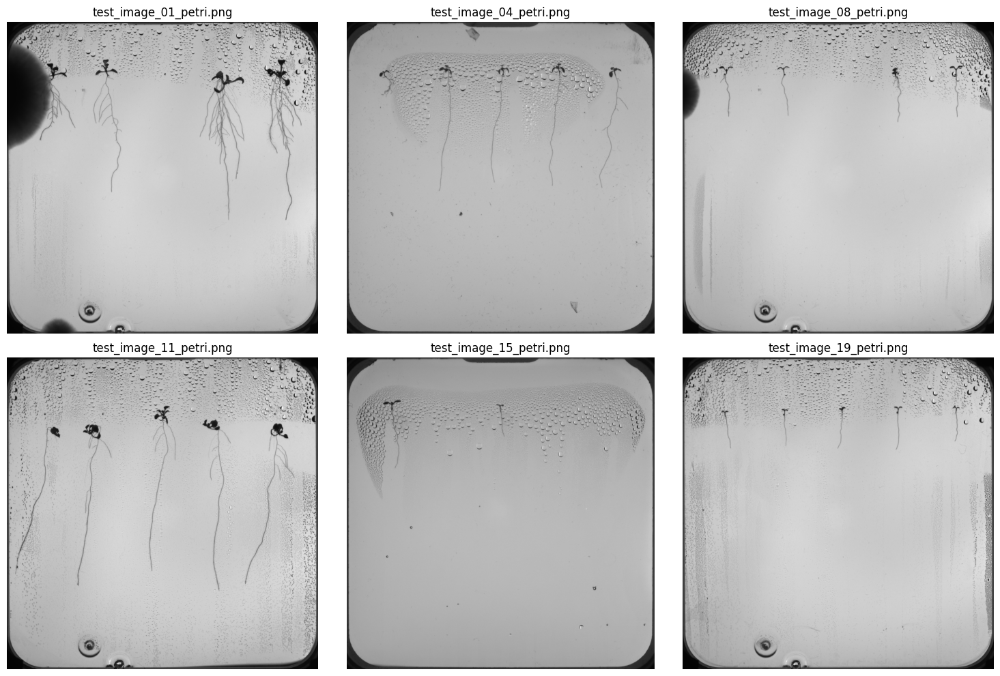

In [7]:
# ============================================================
# CELL 5 — PETRI CROP SANITY CHECK
# ============================================================

show_indices = np.linspace(
    0,
    len(petri_images) - 1,
    6
).astype(int)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10)
)

axes = axes.ravel()

for ax, idx in zip(axes, show_indices):

    path = petri_images[idx]

    bgr = cv2.imread(
        str(path),
        cv2.IMREAD_COLOR
    )

    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(rgb)
    ax.set_title(
        path.name
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# CELL 6 — FULL-RES TASK 5 ROOT SEGMENTATION
# ============================================================

import cv2
import numpy as np
from pathlib import Path

PATCH_SIZE = 512
STRIDE = 384
BATCH_SIZE = 8
ROOT_THRESHOLD = 0.50

PROB_DIR = OUTPUT_DIR / "02_root_probabilities"
MASK_DIR = OUTPUT_DIR / "03_root_masks"

PROB_DIR.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)


def make_blend_window(size=512):
    """
    Smooth weighting window for overlapping patches.
    Small floor prevents zero-weight pixels at image borders.
    """
    w = np.hanning(size).astype(np.float32)

    window = np.outer(w, w)

    window = window / window.max()

    window = np.maximum(
        window,
        0.05
    )

    return window.astype(np.float32)


BLEND_WINDOW = make_blend_window(PATCH_SIZE)


def get_positions(length, patch_size, stride):
    """
    Generate patch positions while guaranteeing coverage
    of the final image edge.
    """

    if length <= patch_size:
        return [0]

    positions = list(
        range(
            0,
            length - patch_size + 1,
            stride
        )
    )

    last = length - patch_size

    if positions[-1] != last:
        positions.append(last)

    return positions


def predict_full_root_mask(
    image_bgr,
    model,
    patch_size=512,
    stride=384,
    batch_size=8
):
    """
    Predict root probability map for one full Petri crop.

    The image is NEVER resized.
    """

    gray = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2GRAY
    ).astype(np.float32) / 255.0

    original_h, original_w = gray.shape

    # Only relevant if a future image is smaller than 512.
    pad_h = max(
        0,
        patch_size - original_h
    )

    pad_w = max(
        0,
        patch_size - original_w
    )

    if pad_h > 0 or pad_w > 0:

        gray = np.pad(
            gray,
            (
                (0, pad_h),
                (0, pad_w)
            ),
            mode="reflect"
        )

    H, W = gray.shape

    ys = get_positions(
        H,
        patch_size,
        stride
    )

    xs = get_positions(
        W,
        patch_size,
        stride
    )

    probability_sum = np.zeros(
        (H, W),
        dtype=np.float32
    )

    weight_sum = np.zeros(
        (H, W),
        dtype=np.float32
    )

    coordinates = [
        (y, x)
        for y in ys
        for x in xs
    ]

    for batch_start in range(
        0,
        len(coordinates),
        batch_size
    ):

        batch_coords = coordinates[
            batch_start:
            batch_start + batch_size
        ]

        patches = []

        for y, x in batch_coords:

            patch = gray[
                y:y + patch_size,
                x:x + patch_size
            ]

            patches.append(
                patch[..., None]
            )

        batch = np.stack(
            patches,
            axis=0
        ).astype(np.float32)

        predictions = root_model(
            batch,
            training=False
        ).numpy()

        predictions = predictions[
            ...,
            0
        ]

        for pred, (y, x) in zip(
            predictions,
            batch_coords
        ):

            probability_sum[
                y:y + patch_size,
                x:x + patch_size
            ] += (
                pred * BLEND_WINDOW
            )

            weight_sum[
                y:y + patch_size,
                x:x + patch_size
            ] += BLEND_WINDOW

    probability = (
        probability_sum /
        np.maximum(
            weight_sum,
            1e-8
        )
    )

    probability = probability[
        :original_h,
        :original_w
    ]

    return probability


# ------------------------------------------------------------
# Run all Kaggle images
# ------------------------------------------------------------

root_prediction_records = []

for i, image_path in enumerate(
    petri_images,
    start=1
):

    print(
        f"[{i:02d}/{len(petri_images)}] "
        f"{image_path.name}"
    )

    bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    assert bgr is not None, (
        f"Could not read {image_path}"
    )

    probability = predict_full_root_mask(
        bgr,
        root_model,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        batch_size=BATCH_SIZE
    )

    mask = (
        probability >= ROOT_THRESHOLD
    ).astype(np.uint8)

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    prob_path = (
        PROB_DIR /
        f"{stem}_root_probability.npy"
    )

    mask_path = (
        MASK_DIR /
        f"{stem}_root_mask.png"
    )

    np.save(
        prob_path,
        probability.astype(np.float16)
    )

    ok = cv2.imwrite(
        str(mask_path),
        mask * 255
    )

    assert ok, (
        f"Could not save {mask_path}"
    )

    root_prediction_records.append({
        "image": stem,
        "height": probability.shape[0],
        "width": probability.shape[1],
        "root_pixels": int(mask.sum()),
        "probability_path": str(prob_path),
        "mask_path": str(mask_path)
    })

print()
print(
    "Finished:",
    len(root_prediction_records),
    "images"
)

[01/19] test_image_01_petri.png


I0000 00:00:1791209365.649719  953832 cuda_dnn.cc:461] Loaded cuDNN version 90701


[02/19] test_image_02_petri.png
[03/19] test_image_03_petri.png
[04/19] test_image_04_petri.png
[05/19] test_image_05_petri.png
[06/19] test_image_06_petri.png
[07/19] test_image_07_petri.png
[08/19] test_image_08_petri.png
[09/19] test_image_09_petri.png
[10/19] test_image_10_petri.png
[11/19] test_image_11_petri.png
[12/19] test_image_12_petri.png
[13/19] test_image_13_petri.png
[14/19] test_image_14_petri.png
[15/19] test_image_15_petri.png
[16/19] test_image_16_petri.png
[17/19] test_image_17_petri.png
[18/19] test_image_18_petri.png
[19/19] test_image_19_petri.png

Finished: 19 images


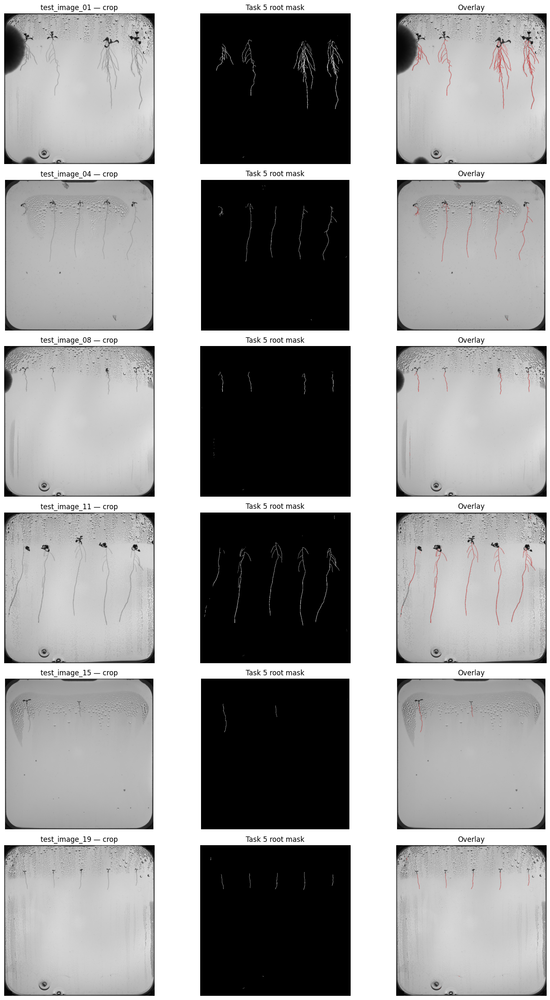

In [9]:
# ============================================================
# CELL 7 — ROOT SEGMENTATION VISUAL CHECK
# ============================================================

import matplotlib.pyplot as plt

check_indices = np.linspace(
    0,
    len(petri_images) - 1,
    6
).astype(int)

fig, axes = plt.subplots(
    len(check_indices),
    3,
    figsize=(15, 4 * len(check_indices))
)

for row, idx in enumerate(check_indices):

    image_path = petri_images[idx]

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    image_bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    mask = cv2.imread(
        str(
            MASK_DIR /
            f"{stem}_root_mask.png"
        ),
        cv2.IMREAD_GRAYSCALE
    )

    mask = mask > 0

    # Resize ONLY the display copy.
    h, w = image_rgb.shape[:2]

    display_width = 700

    scale = min(
        1.0,
        display_width / w
    )

    display_size = (
        int(w * scale),
        int(h * scale)
    )

    rgb_small = cv2.resize(
        image_rgb,
        display_size,
        interpolation=cv2.INTER_AREA
    )

    mask_small = cv2.resize(
        mask.astype(np.uint8),
        display_size,
        interpolation=cv2.INTER_NEAREST
    ).astype(bool)

    overlay = rgb_small.copy()

    overlay[
        mask_small
    ] = (
        0.35 * overlay[mask_small] +
        0.65 * np.array(
            [255, 0, 0]
        )
    ).astype(np.uint8)

    axes[row, 0].imshow(
        rgb_small
    )

    axes[row, 0].set_title(
        f"{stem} — crop"
    )

    axes[row, 1].imshow(
        mask_small,
        cmap="gray"
    )

    axes[row, 1].set_title(
        "Task 5 root mask"
    )

    axes[row, 2].imshow(
        overlay
    )

    axes[row, 2].set_title(
        "Overlay"
    )

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# CELL 8 — DYNAMIC ROOT-ORIGIN DETECTION
# ============================================================

import cv2
import numpy as np
import pandas as pd

from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks


def remove_tiny_components(mask, min_area=20):
    """
    Remove only extremely small isolated predictions.
    Deliberately conservative so young roots survive.
    """

    binary = (mask > 0).astype(np.uint8)

    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )

    cleaned = np.zeros_like(binary)

    for label_id in range(1, n_labels):

        area = stats[
            label_id,
            cv2.CC_STAT_AREA
        ]

        if area >= min_area:
            cleaned[
                labels == label_id
            ] = 1

    return cleaned


def build_root_anchor_score(mask):
    """
    Horizontal score indicating likely plant/root-origin X positions.

    Combines:
    1. root density in the upper part of the plate
    2. how high roots first appear in each column
    """

    H, W = mask.shape

    upper_h = int(H * 0.50)

    upper = mask[
        :upper_h
    ].astype(np.uint8)

    # --------------------------------------------------------
    # Signal 1: amount of root structure in each X column
    # --------------------------------------------------------

    density = upper.sum(
        axis=0
    ).astype(np.float32)

    density = np.log1p(
        density
    )

    sigma = max(
        5,
        int(W * 0.0025)
    )

    density = gaussian_filter1d(
        density,
        sigma=sigma
    )

    # --------------------------------------------------------
    # Signal 2: roots that begin high in the image
    # --------------------------------------------------------

    top_score = np.zeros(
        W,
        dtype=np.float32
    )

    occupied_columns = np.where(
        upper.any(axis=0)
    )[0]

    for x in occupied_columns:

        first_y = int(
            np.argmax(
                upper[:, x] > 0
            )
        )

        top_score[x] = np.exp(
            -first_y / max(1.0, H * 0.15)
        )

    top_score = gaussian_filter1d(
        top_score,
        sigma=sigma
    )

    # --------------------------------------------------------
    # Normalize both signals
    # --------------------------------------------------------

    if density.max() > 0:
        density /= density.max()

    if top_score.max() > 0:
        top_score /= top_score.max()

    combined = (
        0.60 * density +
        0.40 * top_score
    )

    return combined


def find_anchor_x_positions(mask):
    """
    Find an unknown number of candidate plants.
    """

    H, W = mask.shape

    score = build_root_anchor_score(
        mask
    )

    if score.max() <= 0:
        return [], score

    min_distance = max(
        100,
        int(W * 0.075)
    )

    peaks, properties = find_peaks(
        score,
        distance=min_distance,
        height=score.max() * 0.10,
        prominence=score.max() * 0.035
    )

    peaks = sorted(
        int(x)
        for x in peaks
    )

    return peaks, score


def find_supported_start(
    mask,
    anchor_x,
    left_bound,
    right_bound
):
    """
    Find the highest root pixel near an anchor that also
    has genuine downward root support.

    This rejects many isolated false-positive specks.
    """

    H, W = mask.shape

    search_bottom = int(
        H * 0.60
    )

    support_height = max(
        70,
        int(H * 0.055)
    )

    support_radius = max(
        20,
        int(W * 0.012)
    )

    region = mask[
        :search_bottom,
        left_bound:right_bound
    ]

    for y in range(search_bottom):

        row_x = np.flatnonzero(
            region[y]
        )

        if len(row_x) == 0:
            continue

        absolute_x = (
            row_x +
            left_bound
        )

        # Try pixels nearest the anchor first
        order = np.argsort(
            np.abs(
                absolute_x -
                anchor_x
            )
        )

        # No reason to test hundreds of pixels
        for index in order[:10]:

            x = int(
                absolute_x[index]
            )

            y2 = min(
                H,
                y + support_height
            )

            x0 = max(
                left_bound,
                x - support_radius
            )

            x1 = min(
                right_bound,
                x + support_radius + 1
            )

            support = mask[
                y:y2,
                x0:x1
            ]

            total_support = int(
                support.sum()
            )

            halfway = min(
                y2,
                y + support_height // 2
            )

            lower_support = int(
                mask[
                    halfway:y2,
                    x0:x1
                ].sum()
            )

            # Must actually continue downward.
            if (
                total_support >= 25
                and
                lower_support >= 4
            ):
                return (
                    x,
                    y
                )

    return None


def detect_root_origins(mask):
    """
    Complete dynamic detector.

    Returns starts as:
        [(x, y), ...]
    ordered from left to right.
    """

    clean = remove_tiny_components(
        mask,
        min_area=20
    )

    anchors, score = find_anchor_x_positions(
        clean
    )

    if len(anchors) == 0:
        return [], clean, score

    H, W = clean.shape

    starts = []

    for i, anchor_x in enumerate(anchors):

        if i == 0:
            left = 0
        else:
            left = (
                anchors[i - 1] +
                anchor_x
            ) // 2

        if i == len(anchors) - 1:
            right = W
        else:
            right = (
                anchor_x +
                anchors[i + 1]
            ) // 2

        start = find_supported_start(
            clean,
            anchor_x,
            left,
            right
        )

        if start is not None:
            starts.append(start)

    starts = sorted(
        starts,
        key=lambda p: p[0]
    )

    return starts, clean, score

In [11]:
# ============================================================
# CELL 9 — RUN ROOT-ORIGIN DETECTION ON ALL IMAGES
# ============================================================

ROOT_START_DIR = (
    OUTPUT_DIR /
    "04_root_starts"
)

ROOT_START_DIR.mkdir(
    parents=True,
    exist_ok=True
)

root_start_records = []
detected_starts = {}


for image_path in petri_images:

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    mask_path = (
        MASK_DIR /
        f"{stem}_root_mask.png"
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    assert mask is not None, (
        f"Missing root mask: {mask_path}"
    )

    mask = (
        mask > 0
    ).astype(np.uint8)

    starts, clean_mask, score = detect_root_origins(
        mask
    )

    detected_starts[stem] = starts

    print(
        f"{stem}: {len(starts)} starts"
    )

    for plant_index, (x, y) in enumerate(
        starts,
        start=1
    ):

        root_start_records.append({
            "image": stem,
            "plant": plant_index,
            "x": int(x),
            "y": int(y)
        })


root_starts_df = pd.DataFrame(
    root_start_records
)

root_starts_df.to_csv(
    ROOT_START_DIR /
    "detected_root_starts.csv",
    index=False
)

print()
print(
    "Total starts:",
    len(root_starts_df)
)

display(root_starts_df)

test_image_01: 4 starts
test_image_02: 6 starts
test_image_03: 3 starts
test_image_04: 5 starts
test_image_05: 2 starts
test_image_06: 4 starts
test_image_07: 6 starts
test_image_08: 4 starts
test_image_09: 5 starts
test_image_10: 5 starts
test_image_11: 5 starts
test_image_12: 5 starts
test_image_13: 5 starts
test_image_14: 5 starts
test_image_15: 2 starts
test_image_16: 5 starts
test_image_17: 6 starts
test_image_18: 4 starts
test_image_19: 5 starts

Total starts: 86


,image,plant,x,y
0,test_image_01,1,408,573
1,test_image_01,2,916,486
2,test_image_01,3,1943,514
3,test_image_01,4,2423,494
4,test_image_02,1,368,477
...,...,...,...,...
81,test_image_19,1,391,545
82,test_image_19,2,916,529
83,test_image_19,3,1430,521
84,test_image_19,4,1935,507


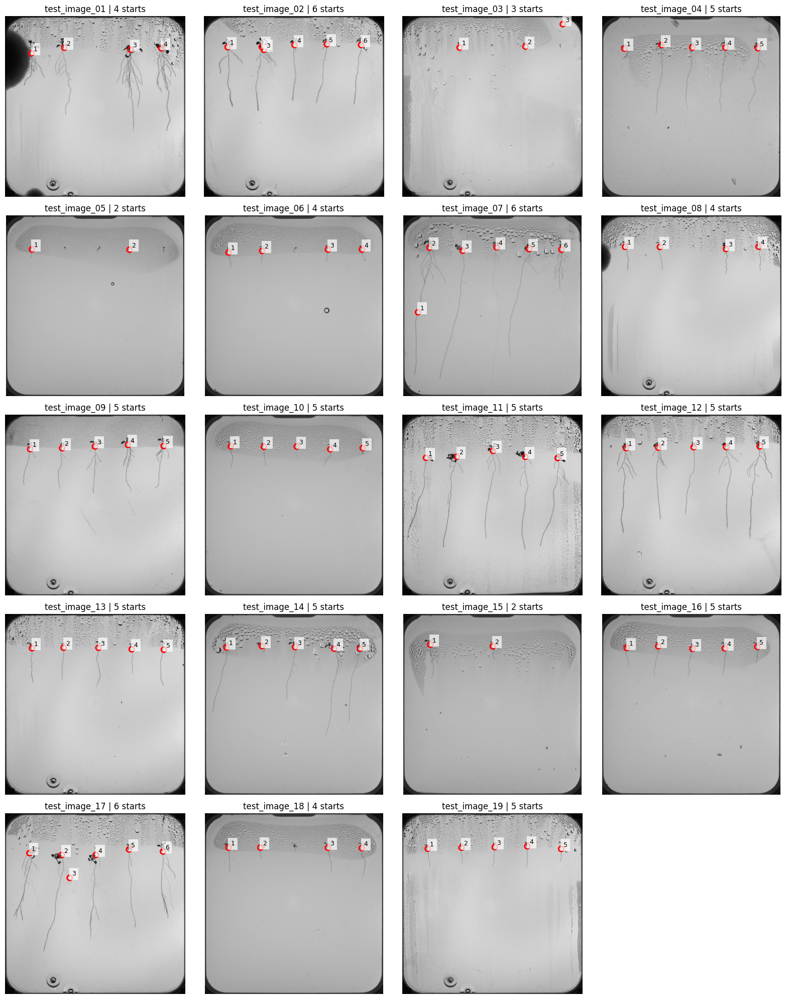

In [12]:
# ============================================================
# CELL 10 — VISUALIZE ROOT STARTS FOR ALL KAGGLE IMAGES
# ============================================================

import matplotlib.pyplot as plt

n_images = len(petri_images)

cols = 4
rows = int(
    np.ceil(
        n_images / cols
    )
)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, 4 * rows)
)

axes = np.asarray(
    axes
).ravel()


for ax, image_path in zip(
    axes,
    petri_images
):

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    starts = detected_starts[
        stem
    ]

    H, W = rgb.shape[:2]

    display_width = 650

    scale = min(
        1.0,
        display_width / W
    )

    small = cv2.resize(
        rgb,
        (
            int(W * scale),
            int(H * scale)
        ),
        interpolation=cv2.INTER_AREA
    )

    ax.imshow(
        small
    )

    for plant_id, (x, y) in enumerate(
        starts,
        start=1
    ):

        xd = x * scale
        yd = y * scale

        ax.scatter(
            xd,
            yd,
            s=55,
            marker="o",
            facecolors="none",
            edgecolors="red",
            linewidths=2
        )

        ax.text(
            xd + 8,
            yd - 8,
            str(plant_id),
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.7,
                edgecolor="none"
            )
        )

    ax.set_title(
        f"{stem} | {len(starts)} starts"
    )

    ax.axis("off")


for ax in axes[
    n_images:
]:
    ax.axis("off")


plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# CELL 11 — V5.1-STYLE MASK-ONLY REFINEMENT
# remove low false starts + rescue tiny roots
# ============================================================

import cv2
import numpy as np
import pandas as pd


def estimate_true_plant_row(mask, starts):
    H, W = mask.shape

    # Trust starts already found in the upper half
    ys = [
        int(y)
        for x, y in starts
        if y < H * 0.45
    ]

    if len(ys) >= 2:
        return int(np.median(ys))

    # Fallback only if preliminary detector found almost nothing
    root_y, root_x = np.where(mask > 0)

    if len(root_y) == 0:
        return int(H * 0.20)

    return int(np.percentile(root_y, 5))


def component_start_candidate(
    labels,
    component_id,
    stats,
    y_offset,
    plant_y
):
    x = int(stats[component_id, cv2.CC_STAT_LEFT])
    y = int(stats[component_id, cv2.CC_STAT_TOP])
    w = int(stats[component_id, cv2.CC_STAT_WIDTH])
    h = int(stats[component_id, cv2.CC_STAT_HEIGHT])
    area = int(stats[component_id, cv2.CC_STAT_AREA])

    ys, xs = np.where(
        labels == component_id
    )

    if len(ys) == 0:
        return None

    absolute_ys = ys + y_offset

    top_y = int(absolute_ys.min())
    bottom_y = int(absolute_ys.max())

    vertical_span = bottom_y - top_y

    # Tiny noise
    if area < 8:
        return None

    if vertical_span < 12:
        return None

    # Candidate must begin near the biological plant row
    row_tolerance = max(
        75,
        int(labels.shape[0] * 0.08)
    )

    if top_y > plant_y + row_tolerance:
        return None

    # Must genuinely continue downward
    if bottom_y < plant_y + 8:
        return None

    # Very tiny candidates should actually look root-like,
    # not like a wide condensation blob.
    verticality = vertical_span / max(w, 1)

    if vertical_span < 35 and verticality < 0.65:
        return None

    # Find the component's highest few root pixels.
    local_top = ys.min()

    top_pixels = np.where(
        (labels == component_id)
        &
        (
            np.indices(labels.shape)[0]
            <= local_top + 6
        )
    )

    if len(top_pixels[0]) == 0:
        return None

    candidate_x = int(
        np.median(top_pixels[1])
    )

    candidate_y = int(
        top_pixels[0].min() + y_offset
    )

    score = (
        vertical_span
        + 0.04 * area
        + 5.0 * verticality
    )

    return {
        "x": candidate_x,
        "y": candidate_y,
        "score": float(score),
        "height": h,
        "width": w,
        "area": area
    }


def refine_root_starts_v51(mask, preliminary_starts):
    """
    Keep trustworthy root-only starts.
    Remove low false detections.
    Rescue tiny root systems near the plant row.
    """

    mask = (mask > 0).astype(np.uint8)

    H, W = mask.shape

    plant_y = estimate_true_plant_row(
        mask,
        preliminary_starts
    )

    # --------------------------------------------------------
    # 1. Remove obvious LOW false detections
    # --------------------------------------------------------

    y_tolerance = max(
        90,
        int(H * 0.055)
    )

    accepted = [
        {
            "x": int(x),
            "y": int(y),
            "score": 1e9,
            "source": "original"
        }
        for x, y in preliminary_starts
        if abs(y - plant_y) <= y_tolerance
    ]

    # --------------------------------------------------------
    # 2. Search only around the biological root-start region
    # --------------------------------------------------------

    band_up = max(
        55,
        int(H * 0.035)
    )

    band_down = max(
        220,
        int(H * 0.12)
    )

    y0 = max(
        0,
        plant_y - band_up
    )

    y1 = min(
        H,
        plant_y + band_down
    )

    band = mask[
        y0:y1
    ]

    n_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            band,
            connectivity=8
        )
    )

    rescue_candidates = []

    border = int(W * 0.02)

    for component_id in range(
        1,
        n_labels
    ):

        candidate = component_start_candidate(
            labels,
            component_id,
            stats,
            y0,
            plant_y
        )

        if candidate is None:
            continue

        x = candidate["x"]

        if x < border or x >= W - border:
            continue

        # If an original start already represents this plant,
        # this component is not a rescue.
        nearest_original = min(
            (
                abs(x - item["x"])
                for item in accepted
            ),
            default=np.inf
        )

        existing_radius = max(
            100,
            int(W * 0.035)
        )

        if nearest_original <= existing_radius:
            continue

        candidate["source"] = "rescue"

        rescue_candidates.append(
            candidate
        )

    # --------------------------------------------------------
    # 3. Combine originals + rescue candidates
    # --------------------------------------------------------

    all_candidates = (
        accepted
        +
        rescue_candidates
    )

    if len(all_candidates) == 0:
        return [], plant_y, []

    all_candidates = sorted(
        all_candidates,
        key=lambda item: item["x"]
    )

    # --------------------------------------------------------
    # 4. Merge candidates that clearly describe same plant
    # --------------------------------------------------------

    merge_distance = max(
        80,
        int(W * 0.028)
    )

    groups = []

    for candidate in all_candidates:

        if not groups:
            groups.append(
                [candidate]
            )
            continue

        if (
            candidate["x"]
            -
            groups[-1][-1]["x"]
            <= merge_distance
        ):
            groups[-1].append(
                candidate
            )

        else:
            groups.append(
                [candidate]
            )

    final = []

    for group in groups:

        # Original detector wins if present.
        originals = [
            g
            for g in group
            if g["source"] == "original"
        ]

        if originals:
            best = originals[0]

        else:
            best = max(
                group,
                key=lambda g: g["score"]
            )

        final.append(
            (
                int(best["x"]),
                int(best["y"])
            )
        )

    final = sorted(
        final,
        key=lambda p: p[0]
    )

    return (
        final,
        plant_y,
        rescue_candidates
    )

In [18]:
# ============================================================
# CELL 12 — RUN V5.1 REFINEMENT
# ============================================================

V51_DIR = OUTPUT_DIR / "05_v51_starts"
V51_DIR.mkdir(
    parents=True,
    exist_ok=True
)

v51_results = {}
v51_records = []

for image_path in petri_images:

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    mask_path = (
        MASK_DIR /
        f"{stem}_root_mask.png"
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    assert mask is not None, (
        f"Missing mask: {mask_path}"
    )

    mask = (
        mask > 0
    ).astype(np.uint8)

    preliminary = detected_starts[
        stem
    ]

    starts, plant_y, rescues = refine_root_starts_v51(
        mask,
        preliminary
    )

    v51_results[stem] = {
        "starts": starts,
        "plant_y": plant_y,
        "rescues": rescues
    }

    print(
        f"{stem}: "
        f"{len(preliminary)} -> {len(starts)} "
        f"(rescued {len(rescues)})"
    )

    for plant_id, (x, y) in enumerate(
        starts,
        start=1
    ):
        v51_records.append({
            "image": stem,
            "plant": plant_id,
            "x": x,
            "y": y
        })


v51_df = pd.DataFrame(
    v51_records
)

v51_df.to_csv(
    V51_DIR / "v51_root_starts.csv",
    index=False
)

print()
print(
    "Final total starts:",
    len(v51_df)
)

test_image_01: 4 -> 4 (rescued 0)
test_image_02: 6 -> 5 (rescued 0)
test_image_03: 3 -> 3 (rescued 1)
test_image_04: 5 -> 5 (rescued 0)
test_image_05: 2 -> 2 (rescued 0)
test_image_06: 4 -> 5 (rescued 1)
test_image_07: 6 -> 5 (rescued 0)
test_image_08: 4 -> 4 (rescued 0)
test_image_09: 5 -> 5 (rescued 0)
test_image_10: 5 -> 5 (rescued 0)
test_image_11: 5 -> 5 (rescued 0)
test_image_12: 5 -> 5 (rescued 0)
test_image_13: 5 -> 5 (rescued 0)
test_image_14: 5 -> 5 (rescued 0)
test_image_15: 2 -> 2 (rescued 0)
test_image_16: 5 -> 5 (rescued 0)
test_image_17: 6 -> 5 (rescued 0)
test_image_18: 4 -> 5 (rescued 1)
test_image_19: 5 -> 5 (rescued 0)

Final total starts: 85


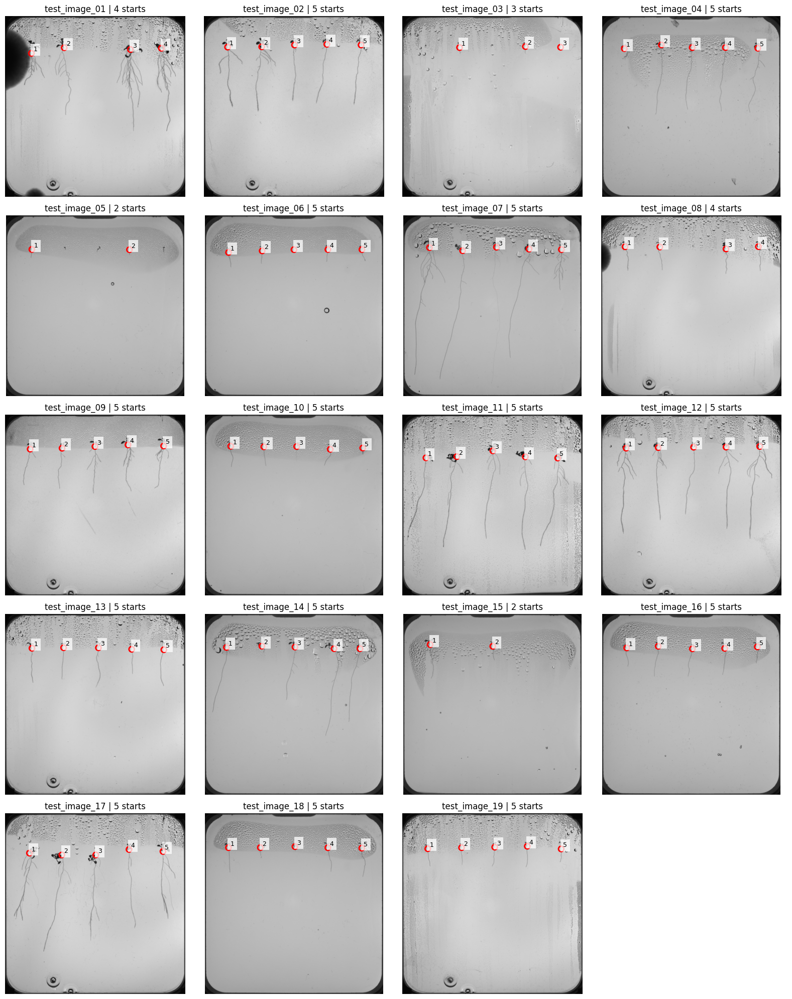

In [19]:
# ============================================================
# CELL 13 — CHECK V5.1 RESULTS
# ============================================================

import matplotlib.pyplot as plt

cols = 4
rows = int(
    np.ceil(
        len(petri_images) / cols
    )
)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, 4 * rows)
)

axes = np.asarray(
    axes
).ravel()


for ax, image_path in zip(
    axes,
    petri_images
):

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    bgr = cv2.imread(
        str(image_path)
    )

    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    result = v51_results[
        stem
    ]

    starts = result[
        "starts"
    ]

    H, W = rgb.shape[:2]

    scale = min(
        1.0,
        650 / W
    )

    small = cv2.resize(
        rgb,
        (
            int(W * scale),
            int(H * scale)
        ),
        interpolation=cv2.INTER_AREA
    )

    ax.imshow(
        small
    )

    for plant_id, (x, y) in enumerate(
        starts,
        start=1
    ):

        ax.scatter(
            x * scale,
            y * scale,
            s=60,
            facecolors="none",
            edgecolors="red",
            linewidths=2
        )

        ax.text(
            x * scale + 7,
            y * scale - 7,
            str(plant_id),
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.75,
                edgecolor="none"
            )
        )

    ax.set_title(
        f"{stem} | {len(starts)} starts"
    )

    ax.axis("off")


for ax in axes[
    len(petri_images):
]:
    ax.axis("off")


plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# TASK 6 — INDIVIDUAL ROOT ASSIGNMENT
# ============================================================
#
# Goal:
# Assign every predicted root component to the correct plant.
#
# Strategy:
# 1. Starts from V5.1 are treated as trusted biological origins.
# 2. Components containing a start are assigned immediately.
# 3. Components containing several starts are split geodesically.
# 4. Disconnected root fragments are attached to the most
#    plausible plant using root-to-root proximity and X alignment.
# 5. Tiny unrelated predictions may remain unassigned as noise.
#
# IMPORTANT:
# No artificial bridge pixels are added to the final root masks.
# ============================================================

import cv2
import heapq
import numpy as np

from scipy.spatial import cKDTree


NEIGHBORS_8 = [
    (-1, -1, np.sqrt(2)),
    (-1,  0, 1.0),
    (-1,  1, np.sqrt(2)),
    ( 0, -1, 1.0),
    ( 0,  1, 1.0),
    ( 1, -1, np.sqrt(2)),
    ( 1,  0, 1.0),
    ( 1,  1, np.sqrt(2)),
]


def snap_start_to_root(mask, x, y, radius=40):
    """
    Snap a V5.1 start onto the nearest real predicted root pixel.
    """

    H, W = mask.shape

    x = int(x)
    y = int(y)

    if (
        0 <= x < W
        and 0 <= y < H
        and mask[y, x]
    ):
        return x, y

    x0 = max(0, x - radius)
    x1 = min(W, x + radius + 1)

    y0 = max(0, y - radius)
    y1 = min(H, y + radius + 1)

    ys, xs = np.where(
        mask[y0:y1, x0:x1] > 0
    )

    if len(ys) == 0:
        return None

    xs = xs + x0
    ys = ys + y0

    d2 = (
        (xs - x) ** 2
        +
        (ys - y) ** 2
    )

    best = int(
        np.argmin(d2)
    )

    return (
        int(xs[best]),
        int(ys[best])
    )


def get_component_info(
    labels,
    stats,
    component_id
):
    """
    Extract useful geometry for one original root component.
    """

    x0 = int(
        stats[
            component_id,
            cv2.CC_STAT_LEFT
        ]
    )

    y0 = int(
        stats[
            component_id,
            cv2.CC_STAT_TOP
        ]
    )

    w = int(
        stats[
            component_id,
            cv2.CC_STAT_WIDTH
        ]
    )

    h = int(
        stats[
            component_id,
            cv2.CC_STAT_HEIGHT
        ]
    )

    area = int(
        stats[
            component_id,
            cv2.CC_STAT_AREA
        ]
    )

    local = (
        labels[
            y0:y0 + h,
            x0:x0 + w
        ]
        ==
        component_id
    )

    ly, lx = np.where(local)

    gy = ly + y0
    gx = lx + x0

    top_y = int(
        gy.min()
    )

    bottom_y = int(
        gy.max()
    )

    top_band = (
        gy <= top_y + 12
    )

    top_x = int(
        np.median(
            gx[top_band]
        )
    )

    top_points = np.column_stack(
        (
            gy[top_band],
            gx[top_band]
        )
    )

    all_points = np.column_stack(
        (
            gy,
            gx
        )
    )

    return {
        "id": component_id,
        "area": area,
        "x0": x0,
        "y0": y0,
        "width": w,
        "height": h,
        "top_y": top_y,
        "bottom_y": bottom_y,
        "vertical_span": bottom_y - top_y,
        "top_x": top_x,
        "top_points": top_points,
        "points": all_points
    }


def split_multi_start_component(
    labels,
    stats,
    component_id,
    seeds,
    final_owner
):
    """
    If roots from multiple plants actually touch in the
    segmentation, split only that connected structure using
    geodesic distance along genuine root pixels.
    """

    x0 = int(
        stats[
            component_id,
            cv2.CC_STAT_LEFT
        ]
    )

    y0 = int(
        stats[
            component_id,
            cv2.CC_STAT_TOP
        ]
    )

    w = int(
        stats[
            component_id,
            cv2.CC_STAT_WIDTH
        ]
    )

    h = int(
        stats[
            component_id,
            cv2.CC_STAT_HEIGHT
        ]
    )

    component = (
        labels[
            y0:y0 + h,
            x0:x0 + w
        ]
        ==
        component_id
    )

    distance = np.full(
        component.shape,
        np.inf,
        dtype=np.float32
    )

    owner = np.zeros(
        component.shape,
        dtype=np.int32
    )

    queue = []

    for plant_id, sx, sy in seeds:

        lx = sx - x0
        ly = sy - y0

        distance[
            ly,
            lx
        ] = 0.0

        owner[
            ly,
            lx
        ] = plant_id

        heapq.heappush(
            queue,
            (
                0.0,
                ly,
                lx,
                plant_id
            )
        )

    while queue:

        dist, y, x, plant_id = heapq.heappop(
            queue
        )

        if dist > distance[y, x]:
            continue

        for dy, dx, step in NEIGHBORS_8:

            ny = y + dy
            nx = x + dx

            if not (
                0 <= ny < h
                and
                0 <= nx < w
            ):
                continue

            if not component[ny, nx]:
                continue

            new_dist = dist + step

            if new_dist < distance[ny, nx]:

                distance[
                    ny,
                    nx
                ] = new_dist

                owner[
                    ny,
                    nx
                ] = plant_id

                heapq.heappush(
                    queue,
                    (
                        new_dist,
                        ny,
                        nx,
                        plant_id
                    )
                )

    roi = final_owner[
        y0:y0 + h,
        x0:x0 + w
    ]

    roi[
        component
    ] = owner[
        component
    ]


def build_plant_trees(
    owner_map,
    plant_ids,
    max_points=25000
):
    """
    KD-trees provide fast distance from a disconnected
    root component to roots already owned by each plant.
    """

    trees = {}

    for plant_id in plant_ids:

        coords = np.argwhere(
            owner_map == plant_id
        )

        if len(coords) == 0:
            trees[
                plant_id
            ] = None

            continue

        if len(coords) > max_points:

            step = int(
                np.ceil(
                    len(coords)
                    /
                    max_points
                )
            )

            coords = coords[
                ::step
            ]

        trees[
            plant_id
        ] = cKDTree(
            coords
        )

    return trees


def assign_roots_to_plants(
    mask,
    starts
):
    """
    Robust individual-root assignment.

    Works on the ORIGINAL Task 5 mask.
    """

    mask = (
        mask > 0
    ).astype(np.uint8)

    H, W = mask.shape

    final_owner = np.zeros(
        (H, W),
        dtype=np.int32
    )

    # --------------------------------------------------------
    # Snap trusted V5.1 origins to real mask pixels
    # --------------------------------------------------------

    snapped_starts = []

    for plant_id, (x, y) in enumerate(
        starts,
        start=1
    ):

        snapped = snap_start_to_root(
            mask,
            x,
            y
        )

        if snapped is None:
            raise RuntimeError(
                f"Plant {plant_id}: "
                f"no root pixel near start ({x}, {y})"
            )

        sx, sy = snapped

        snapped_starts.append(
            (
                plant_id,
                sx,
                sy
            )
        )

    plant_ids = [
        p[0]
        for p in snapped_starts
    ]

    start_lookup = {
        plant_id: (
            x,
            y
        )
        for plant_id, x, y
        in snapped_starts
    }

    # --------------------------------------------------------
    # Original Task 5 connected components
    # --------------------------------------------------------

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    components = {}

    for component_id in range(
        1,
        n_labels
    ):

        components[
            component_id
        ] = get_component_info(
            labels,
            stats,
            component_id
        )

    # --------------------------------------------------------
    # Which components contain biological starts?
    # --------------------------------------------------------

    component_seeds = {}

    for plant_id, x, y in snapped_starts:

        component_id = int(
            labels[
                y,
                x
            ]
        )

        component_seeds.setdefault(
            component_id,
            []
        ).append(
            (
                plant_id,
                x,
                y
            )
        )

    assigned_components = set()

    # --------------------------------------------------------
    # Seeded components
    # --------------------------------------------------------

    for component_id, seeds in component_seeds.items():

        if component_id == 0:
            continue

        component = (
            labels == component_id
        )

        if len(seeds) == 1:

            plant_id = seeds[
                0
            ][0]

            final_owner[
                component
            ] = plant_id

        else:

            split_multi_start_component(
                labels,
                stats,
                component_id,
                seeds,
                final_owner
            )

        assigned_components.add(
            component_id
        )

    # --------------------------------------------------------
    # Root spacing gives us a biological scale.
    # --------------------------------------------------------

    start_xs = sorted(
        x
        for _, x, _
        in snapped_starts
    )

    if len(start_xs) >= 2:

        median_spacing = float(
            np.median(
                np.diff(
                    start_xs
                )
            )
        )

    else:

        median_spacing = (
            W * 0.5
        )

    # --------------------------------------------------------
    # Unseeded components
    # --------------------------------------------------------

    remaining = {
        cid
        for cid in components
        if cid not in assigned_components
    }

    # Attach from top downward.
    # Several passes allow chains of disconnected fragments.
    for _ in range(4):

        if not remaining:
            break

        trees = build_plant_trees(
            final_owner,
            plant_ids
        )

        newly_assigned = []

        ordered_components = sorted(
            remaining,
            key=lambda cid:
                components[
                    cid
                ]["top_y"]
        )

        for component_id in ordered_components:

            info = components[
                component_id
            ]

            # Ignore obvious microscopic noise.
            if (
                info["area"] < 8
                or
                info["vertical_span"] < 5
            ):
                continue

            best_plant = None
            best_score = np.inf
            best_root_distance = np.inf

            for plant_id in plant_ids:

                tree = trees[
                    plant_id
                ]

                if tree is None:
                    continue

                sx, sy = start_lookup[
                    plant_id
                ]

                # Component should not begin far above its plant.
                if (
                    info["top_y"]
                    <
                    sy - 80
                ):
                    continue

                distances, _ = tree.query(
                    info[
                        "top_points"
                    ],
                    k=1
                )

                nearest_root_distance = float(
                    np.min(
                        distances
                    )
                )

                horizontal_offset = abs(
                    info["top_x"]
                    -
                    sx
                )

                # Root-to-root distance matters most.
                # X position only breaks ambiguity.
                score = (
                    nearest_root_distance
                    +
                    0.18
                    *
                    horizontal_offset
                )

                if score < best_score:

                    best_score = score
                    best_plant = plant_id

                    best_root_distance = (
                        nearest_root_distance
                    )

            if best_plant is None:
                continue

            max_gap = max(
                130,
                int(H * 0.065)
            )

            sx, sy = start_lookup[
                best_plant
            ]

            horizontal_offset = abs(
                info["top_x"]
                -
                sx
            )

            strong_x_alignment = (
                horizontal_offset
                <=
                median_spacing * 0.32
            )

            root_like = (
                info["vertical_span"]
                >= 12
            )

            if (
                best_root_distance
                <= max_gap
                or
                (
                    strong_x_alignment
                    and
                    root_like
                )
            ):

                final_owner[
                    labels
                    ==
                    component_id
                ] = best_plant

                newly_assigned.append(
                    component_id
                )

        for cid in newly_assigned:

            remaining.discard(
                cid
            )

        if len(newly_assigned) == 0:
            break

    # --------------------------------------------------------
    # Conservative final rescue
    #
    # Remaining root-like fragments can still be separated
    # by a larger segmentation gap. Assign only when their X
    # position strongly agrees with a plant.
    # --------------------------------------------------------

    for component_id in list(
        remaining
    ):

        info = components[
            component_id
        ]

        if (
            info["area"] < 10
            or
            info["vertical_span"] < 10
        ):
            continue

        candidate_plants = []

        for plant_id in plant_ids:

            sx, sy = start_lookup[
                plant_id
            ]

            if (
                info["top_y"]
                <
                sy - 80
            ):
                continue

            x_distance = abs(
                info["top_x"]
                -
                sx
            )

            candidate_plants.append(
                (
                    x_distance,
                    plant_id
                )
            )

        if not candidate_plants:
            continue

        x_distance, plant_id = min(
            candidate_plants
        )

        if (
            x_distance
            <=
            median_spacing * 0.45
        ):

            final_owner[
                labels
                ==
                component_id
            ] = plant_id

    return (
        final_owner,
        snapped_starts
    )

In [27]:
# ============================================================
# TASK 6 — RUN INDIVIDUAL ROOT ASSIGNMENT
# ============================================================

from pathlib import Path
import pandas as pd


INDIVIDUAL_ROOT_DIR = (
    OUTPUT_DIR /
    "06_individual_roots"
)

INDIVIDUAL_ROOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

task6_results = {}
task6_records = []


for image_path in petri_images:

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    mask_path = (
        MASK_DIR /
        f"{stem}_root_mask.png"
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    assert mask is not None, (
        f"Missing root mask: {mask_path}"
    )

    mask = (
        mask > 0
    ).astype(np.uint8)

    starts = v51_results[
        stem
    ]["starts"]

    owner_map, snapped_starts = (
        assign_roots_to_plants(
            mask,
            starts
        )
    )

    image_dir = (
        INDIVIDUAL_ROOT_DIR /
        stem
    )

    image_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    individual_masks = {}

    for plant_id, x, y in snapped_starts:

        plant_mask = (
            owner_map
            ==
            plant_id
        ).astype(np.uint8)

        pixel_count = int(
            plant_mask.sum()
        )

        individual_masks[
            plant_id
        ] = plant_mask

        save_path = (
            image_dir /
            f"plant_{plant_id:02d}.png"
        )

        ok = cv2.imwrite(
            str(save_path),
            plant_mask * 255
        )

        assert ok, (
            f"Could not save {save_path}"
        )

        task6_records.append({
            "image": stem,
            "plant": plant_id,
            "start_x": x,
            "start_y": y,
            "root_pixels": pixel_count
        })

    # Save the complete ownership map as well.
    np.save(
        image_dir /
        "owner_map.npy",
        owner_map.astype(np.uint8)
    )

    task6_results[
        stem
    ] = {
        "owner_map": owner_map,
        "starts": snapped_starts,
        "individual_masks": individual_masks
    }

    counts = [
        int(
            individual_masks[p].sum()
        )
        for p in individual_masks
    ]

    print(
        f"{stem}: "
        f"{len(individual_masks)} plants | "
        f"pixels={counts}"
    )


task6_df = pd.DataFrame(
    task6_records
)

task6_df.to_csv(
    INDIVIDUAL_ROOT_DIR /
    "task6_root_assignment.csv",
    index=False
)

print()
print(
    "Task 6 complete:",
    len(task6_df),
    "individual root systems"
)

test_image_01: 4 plants | pixels=[8843, 11725, 35371, 26588]
test_image_02: 5 plants | pixels=[10146, 12607, 5522, 5456, 6418]
test_image_03: 3 plants | pixels=[529, 516, 92]
test_image_04: 5 plants | pixels=[1627, 5515, 4218, 4886, 6051]
test_image_05: 2 plants | pixels=[584, 366]
test_image_06: 5 plants | pixels=[1144, 912, 240, 827, 812]
test_image_07: 5 plants | pixels=[19140, 10052, 4501, 11554, 8660]
test_image_08: 4 plants | pixels=[2594, 1952, 2484, 1911]
test_image_09: 5 plants | pixels=[3615, 4077, 7495, 9541, 7995]
test_image_10: 5 plants | pixels=[1529, 1289, 556, 1190, 496]
test_image_11: 5 plants | pixels=[4653, 12125, 10277, 10739, 12821]
test_image_12: 5 plants | pixels=[15380, 10986, 5734, 11212, 17598]
test_image_13: 5 plants | pixels=[3267, 2648, 3566, 1854, 3296]
test_image_14: 5 plants | pixels=[5064, 541, 4654, 7745, 5962]
test_image_15: 2 plants | pixels=[2283, 889]
test_image_16: 5 plants | pixels=[1277, 2087, 2032, 1956, 1266]
test_image_17: 5 plants | pixels=[

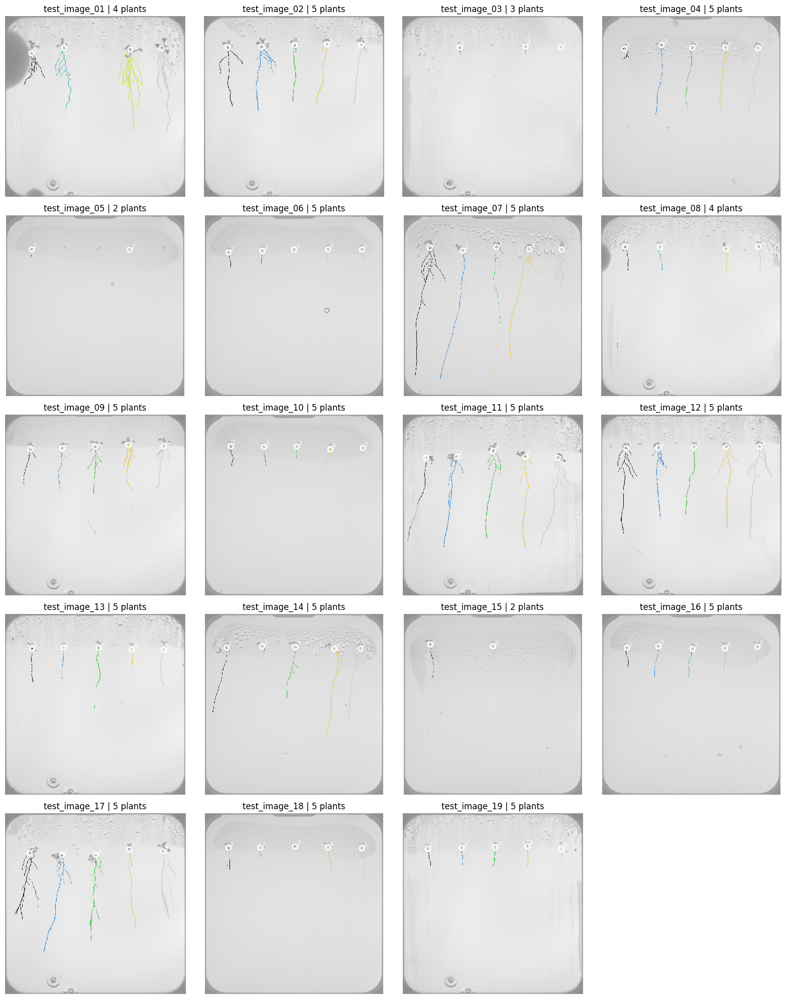

In [28]:
# ============================================================
# TASK 6 — FINAL VISUAL QUALITY CHECK
# ============================================================

import matplotlib.pyplot as plt


cols = 4

rows = int(
    np.ceil(
        len(petri_images)
        /
        cols
    )
)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, 4 * rows)
)

axes = np.asarray(
    axes
).ravel()


for ax, image_path in zip(
    axes,
    petri_images
):

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    result = task6_results[
        stem
    ]

    owner = result[
        "owner_map"
    ]

    starts = result[
        "starts"
    ]

    H, W = rgb.shape[:2]

    display_width = 600

    scale = min(
        1.0,
        display_width / W
    )

    display_size = (
        int(W * scale),
        int(H * scale)
    )

    rgb_small = cv2.resize(
        rgb,
        display_size,
        interpolation=cv2.INTER_AREA
    )

    owner_small = cv2.resize(
        owner.astype(np.uint8),
        display_size,
        interpolation=cv2.INTER_NEAREST
    )

    ax.imshow(
        rgb_small,
        alpha=0.45
    )

    masked_owner = np.ma.masked_where(
        owner_small == 0,
        owner_small
    )

    ax.imshow(
        masked_owner,
        cmap="nipy_spectral",
        interpolation="nearest",
        alpha=0.9
    )

    for plant_id, x, y in starts:

        ax.scatter(
            x * scale,
            y * scale,
            s=50,
            facecolors="none",
            edgecolors="white",
            linewidths=2
        )

        ax.text(
            x * scale + 6,
            y * scale - 6,
            str(plant_id),
            fontsize=8,
            color="white"
        )

    ax.set_title(
        f"{stem} | {len(starts)} plants"
    )

    ax.axis("off")


for ax in axes[
    len(petri_images):
]:
    ax.axis("off")


plt.tight_layout()
plt.show()

# WAIT WHAT IS THIS WE NEED TO CHWCK THRESHOLDS

In [29]:
# ============================================================
# THRESHOLD SANITY TEST — 0.50 VS 0.35
# ============================================================
#
# YOUR MODEL IS NOT CHANGED.
#
# We reuse the exact probability maps already produced by
# Task 5 and compare two binary thresholds.
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


THRESHOLD_A = 0.50
THRESHOLD_B = 0.35


def snap_to_mask(mask, x, y, radius=40):
    H, W = mask.shape

    x = int(x)
    y = int(y)

    if (
        0 <= x < W
        and 0 <= y < H
        and mask[y, x]
    ):
        return x, y

    x0 = max(0, x - radius)
    x1 = min(W, x + radius + 1)

    y0 = max(0, y - radius)
    y1 = min(H, y + radius + 1)

    ys, xs = np.where(
        mask[y0:y1, x0:x1] > 0
    )

    if len(ys) == 0:
        return None

    xs = xs + x0
    ys = ys + y0

    d2 = (
        (xs - x) ** 2
        +
        (ys - y) ** 2
    )

    idx = int(
        np.argmin(d2)
    )

    return (
        int(xs[idx]),
        int(ys[idx])
    )


def component_span_from_start(
    mask,
    start
):
    """
    Measure how far downward the connected root structure
    extends from one trusted V5.1 start.
    """

    snapped = snap_to_mask(
        mask,
        start[0],
        start[1]
    )

    if snapped is None:
        return 0, 0

    x, y = snapped

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask.astype(np.uint8),
            connectivity=8
        )
    )

    component_id = int(
        labels[y, x]
    )

    if component_id == 0:
        return 0, 0

    ys, xs = np.where(
        labels == component_id
    )

    vertical_span = int(
        ys.max() - ys.min()
    )

    area = int(
        len(ys)
    )

    return (
        vertical_span,
        area
    )


threshold_records = []

for image_path in petri_images:

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    probability = np.load(
        PROB_DIR /
        f"{stem}_root_probability.npy"
    ).astype(np.float32)

    starts = v51_results[
        stem
    ]["starts"]

    for threshold_name, threshold in [
        ("0.50", THRESHOLD_A),
        ("0.35", THRESHOLD_B)
    ]:

        mask = (
            probability >= threshold
        ).astype(np.uint8)

        spans = []
        areas = []

        for start in starts:

            span, area = component_span_from_start(
                mask,
                start
            )

            spans.append(span)
            areas.append(area)

        threshold_records.append({
            "image": stem,
            "threshold": threshold_name,
            "root_pixels": int(mask.sum()),
            "mean_start_component_span": float(
                np.mean(spans)
            ),
            "median_start_component_span": float(
                np.median(spans)
            ),
            "mean_start_component_area": float(
                np.mean(areas)
            )
        })


threshold_df = pd.DataFrame(
    threshold_records
)

display(
    threshold_df
)

,image,threshold,root_pixels,mean_start_component_span,median_start_component_span,mean_start_component_area
0,test_image_01,0.50,82587,452.750000,255.0,8772.750000
1,test_image_01,0.35,83927,453.000000,255.0,8941.750000
2,test_image_02,0.50,41147,933.400000,928.0,7931.800000
3,test_image_02,0.35,41795,933.800000,928.0,8023.800000
4,test_image_03,0.50,2004,76.333333,95.0,330.333333
5,test_image_03,0.35,2173,77.000000,96.0,338.666667
6,test_image_04,0.50,22627,476.000000,254.0,2462.000000
7,test_image_04,0.35,22992,476.600000,255.0,2494.800000
8,test_image_05,0.50,961,107.500000,107.5,475.000000
9,test_image_05,0.35,976,108.000000,108.0,480.000000


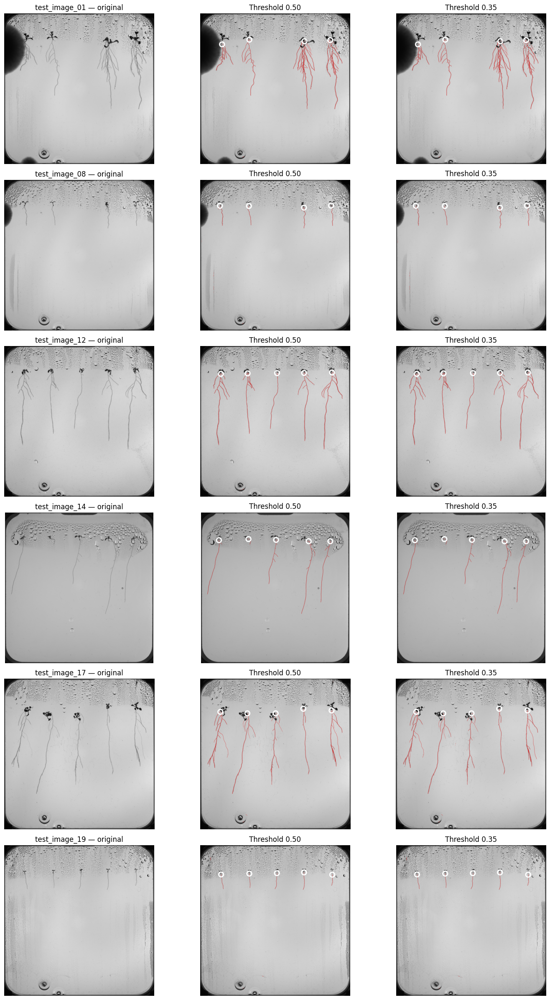

In [30]:
# ============================================================
# VISUAL THRESHOLD COMPARISON
# ============================================================

CHECK_IMAGES = [
    "test_image_01",
    "test_image_08",
    "test_image_12",
    "test_image_14",
    "test_image_17",
    "test_image_19"
]


fig, axes = plt.subplots(
    len(CHECK_IMAGES),
    3,
    figsize=(15, 4 * len(CHECK_IMAGES))
)


for row, stem in enumerate(
    CHECK_IMAGES
):

    image_path = next(
        p
        for p in petri_images
        if p.stem.replace(
            "_petri",
            ""
        ) == stem
    )

    bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    probability = np.load(
        PROB_DIR /
        f"{stem}_root_probability.npy"
    ).astype(np.float32)

    mask_050 = (
        probability >= THRESHOLD_A
    )

    mask_035 = (
        probability >= THRESHOLD_B
    )

    overlay_050 = rgb.copy()
    overlay_035 = rgb.copy()

    overlay_050[
        mask_050
    ] = (
        0.35 * overlay_050[mask_050]
        +
        0.65 * np.array(
            [255, 0, 0]
        )
    ).astype(np.uint8)

    overlay_035[
        mask_035
    ] = (
        0.35 * overlay_035[mask_035]
        +
        0.65 * np.array(
            [255, 0, 0]
        )
    ).astype(np.uint8)

    axes[row, 0].imshow(
        rgb
    )

    axes[row, 0].set_title(
        f"{stem} — original"
    )

    axes[row, 1].imshow(
        overlay_050
    )

    axes[row, 1].set_title(
        "Threshold 0.50"
    )

    axes[row, 2].imshow(
        overlay_035
    )

    axes[row, 2].set_title(
        "Threshold 0.35"
    )

    # Same trusted V5.1 starts on both
    starts = v51_results[
        stem
    ]["starts"]

    for x, y in starts:

        axes[row, 1].scatter(
            x,
            y,
            s=70,
            facecolors="none",
            edgecolors="white",
            linewidths=2
        )

        axes[row, 2].scatter(
            x,
            y,
            s=70,
            facecolors="none",
            edgecolors="white",
            linewidths=2
        )

    for col in range(3):
        axes[row, col].axis("off")


plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# TASK 6 THRESHOLD COMPARISON — 0.50 VS 0.35
# ============================================================
#
# Same model.
# Same probability maps.
# Same V5.1 starts.
# Same Task 6 algorithm.
#
# ONLY the binary threshold changes.
# ============================================================

THRESHOLDS = {
    "0.50": 0.50,
    "0.35": 0.35
}

task6_threshold_results = {}

for threshold_name, threshold in THRESHOLDS.items():

    print(f"\n===== THRESHOLD {threshold_name} =====")

    threshold_results = {}

    for image_path in petri_images:

        stem = image_path.stem.replace(
            "_petri",
            ""
        )

        probability = np.load(
            PROB_DIR /
            f"{stem}_root_probability.npy"
        ).astype(np.float32)

        mask = (
            probability >= threshold
        ).astype(np.uint8)

        starts = v51_results[
            stem
        ]["starts"]

        owner_map, snapped_starts = assign_roots_to_plants(
            mask,
            starts
        )

        threshold_results[
            stem
        ] = {
            "mask": mask,
            "owner_map": owner_map,
            "starts": snapped_starts
        }

        print(
            f"{stem}: "
            f"{len(snapped_starts)} plants | "
            f"assigned pixels={int((owner_map > 0).sum()):,}"
        )

    task6_threshold_results[
        threshold_name
    ] = threshold_results


===== THRESHOLD 0.50 =====
test_image_01: 4 plants | assigned pixels=82,529
test_image_02: 5 plants | assigned pixels=40,151
test_image_03: 3 plants | assigned pixels=1,137
test_image_04: 5 plants | assigned pixels=22,298
test_image_05: 2 plants | assigned pixels=950
test_image_06: 5 plants | assigned pixels=3,935
test_image_07: 5 plants | assigned pixels=53,909
test_image_08: 4 plants | assigned pixels=8,941
test_image_09: 5 plants | assigned pixels=32,723
test_image_10: 5 plants | assigned pixels=5,060
test_image_11: 5 plants | assigned pixels=50,615
test_image_12: 5 plants | assigned pixels=60,910
test_image_13: 5 plants | assigned pixels=14,631
test_image_14: 5 plants | assigned pixels=23,966
test_image_15: 2 plants | assigned pixels=3,172
test_image_16: 5 plants | assigned pixels=8,618
test_image_17: 5 plants | assigned pixels=63,307
test_image_18: 5 plants | assigned pixels=6,638
test_image_19: 5 plants | assigned pixels=6,417

===== THRESHOLD 0.35 =====
test_image_01: 4 plants 

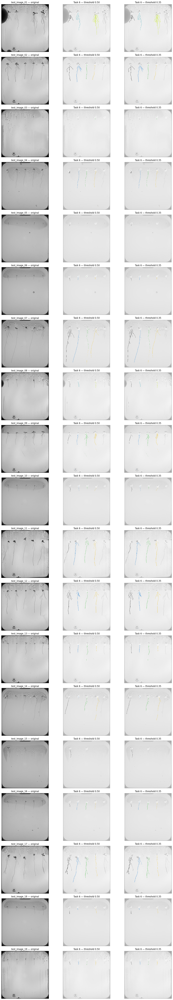

In [32]:
# ============================================================
# TASK 6 VISUAL COMPARISON — 0.50 VS 0.35
# ============================================================

import matplotlib.pyplot as plt

cols = 3
rows = len(petri_images)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(15, 4 * rows)
)

for row, image_path in enumerate(petri_images):

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    H, W = rgb.shape[:2]

    display_width = 650

    scale = min(
        1.0,
        display_width / W
    )

    display_size = (
        int(W * scale),
        int(H * scale)
    )

    rgb_small = cv2.resize(
        rgb,
        display_size,
        interpolation=cv2.INTER_AREA
    )

    axes[row, 0].imshow(
        rgb_small
    )

    axes[row, 0].set_title(
        f"{stem} — original"
    )

    axes[row, 0].axis("off")

    for col, threshold_name in enumerate(
        ["0.50", "0.35"],
        start=1
    ):

        result = task6_threshold_results[
            threshold_name
        ][stem]

        owner = result[
            "owner_map"
        ]

        starts = result[
            "starts"
        ]

        owner_small = cv2.resize(
            owner.astype(np.uint8),
            display_size,
            interpolation=cv2.INTER_NEAREST
        )

        axes[row, col].imshow(
            rgb_small,
            alpha=0.35
        )

        masked_owner = np.ma.masked_where(
            owner_small == 0,
            owner_small
        )

        axes[row, col].imshow(
            masked_owner,
            cmap="nipy_spectral",
            interpolation="nearest",
            alpha=0.95
        )

        for plant_id, x, y in starts:

            axes[row, col].scatter(
                x * scale,
                y * scale,
                s=55,
                facecolors="none",
                edgecolors="white",
                linewidths=2
            )

            axes[row, col].text(
                x * scale + 6,
                y * scale - 6,
                str(plant_id),
                fontsize=8,
                color="white"
            )

        axes[row, col].set_title(
            f"Task 6 — threshold {threshold_name}"
        )

        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# HOW MANY PIXELS ACTUALLY CHANGE BETWEEN 0.50 AND 0.35?
# ============================================================

for image_path in petri_images:

    stem = image_path.stem.replace("_petri", "")

    probability = np.load(
        PROB_DIR / f"{stem}_root_probability.npy"
    ).astype(np.float32)

    mask_050 = probability >= 0.50
    mask_035 = probability >= 0.35

    added_pixels = np.logical_and(
        mask_035,
        ~mask_050
    ).sum()

    root_050 = mask_050.sum()
    root_035 = mask_035.sum()

    pct_change = (
        100 * added_pixels / max(root_050, 1)
    )

    print(
        f"{stem}: "
        f"0.50={root_050:,} | "
        f"0.35={root_035:,} | "
        f"added={added_pixels:,} "
        f"({pct_change:.2f}%)"
    )

test_image_01: 0.50=82,587 | 0.35=83,927 | added=1,340 (1.62%)
test_image_02: 0.50=41,147 | 0.35=41,795 | added=648 (1.57%)
test_image_03: 0.50=2,004 | 0.35=2,173 | added=169 (8.43%)
test_image_04: 0.50=22,627 | 0.35=22,992 | added=365 (1.61%)
test_image_05: 0.50=961 | 0.35=976 | added=15 (1.56%)
test_image_06: 0.50=3,935 | 0.35=3,972 | added=37 (0.94%)
test_image_07: 0.50=53,950 | 0.35=54,740 | added=790 (1.46%)
test_image_08: 0.50=9,086 | 0.35=9,335 | added=249 (2.74%)
test_image_09: 0.50=33,030 | 0.35=33,571 | added=541 (1.64%)
test_image_10: 0.50=5,071 | 0.35=5,186 | added=115 (2.27%)
test_image_11: 0.50=50,967 | 0.35=51,647 | added=680 (1.33%)
test_image_12: 0.50=61,053 | 0.35=61,678 | added=625 (1.02%)
test_image_13: 0.50=14,677 | 0.35=14,920 | added=243 (1.66%)
test_image_14: 0.50=24,077 | 0.35=24,323 | added=246 (1.02%)
test_image_15: 0.50=3,197 | 0.35=3,291 | added=94 (2.94%)
test_image_16: 0.50=8,622 | 0.35=8,724 | added=102 (1.18%)
test_image_17: 0.50=63,388 | 0.35=64,267 | 

test_image_12: raw=61,053 | assigned=60,910 | LOST=143 (0.23%)
test_image_14: raw=24,077 | assigned=23,966 | LOST=111 (0.46%)
test_image_17: raw=63,387 | assigned=63,306 | LOST=81 (0.13%)


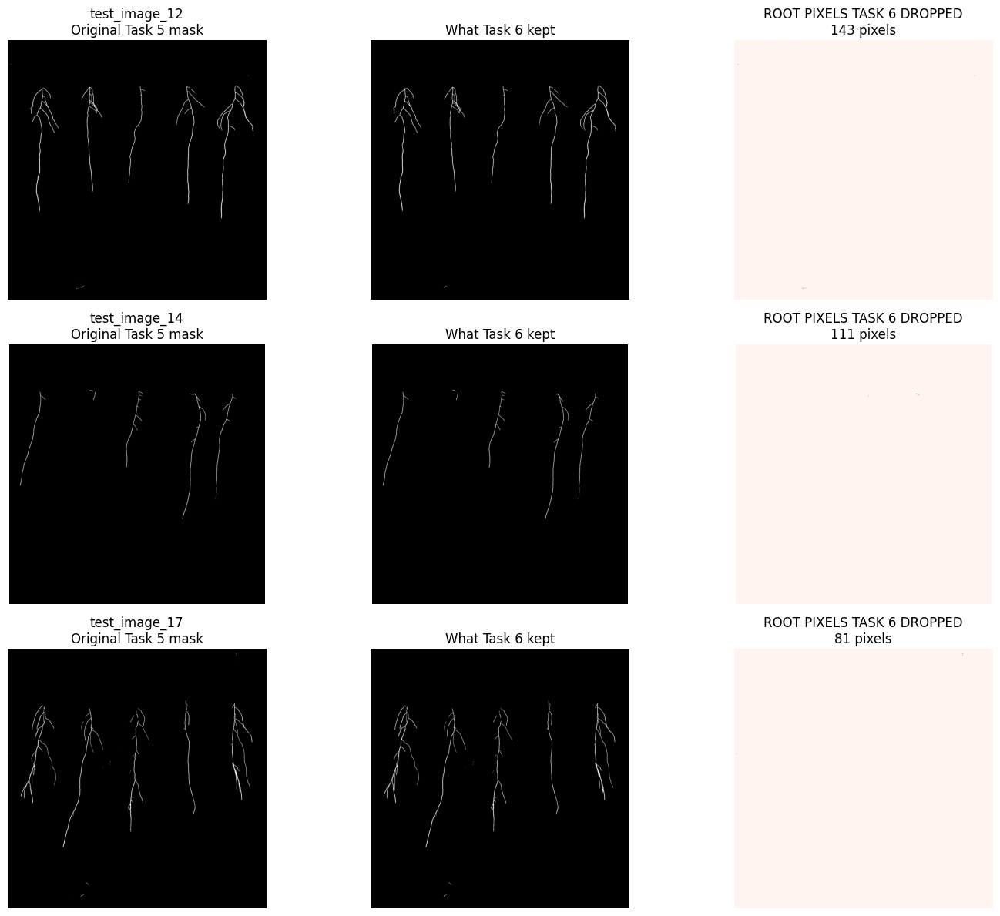

In [34]:
# ============================================================
# TASK 6 DIAGNOSTIC — WHAT ROOT PIXELS ARE BEING LOST?
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

check_images = [
    "test_image_12",
    "test_image_14",
    "test_image_17"
]

fig, axes = plt.subplots(
    len(check_images),
    3,
    figsize=(15, 4 * len(check_images))
)

for row, stem in enumerate(check_images):

    raw_mask = cv2.imread(
        str(
            MASK_DIR /
            f"{stem}_root_mask.png"
        ),
        cv2.IMREAD_GRAYSCALE
    ) > 0

    owner = task6_results[
        stem
    ]["owner_map"]

    assigned = owner > 0

    lost = (
        raw_mask
        &
        ~assigned
    )

    raw_pixels = int(raw_mask.sum())
    assigned_pixels = int(assigned.sum())
    lost_pixels = int(lost.sum())

    print(
        f"{stem}: "
        f"raw={raw_pixels:,} | "
        f"assigned={assigned_pixels:,} | "
        f"LOST={lost_pixels:,} "
        f"({100*lost_pixels/max(raw_pixels,1):.2f}%)"
    )

    axes[row, 0].imshow(
        raw_mask,
        cmap="gray"
    )
    axes[row, 0].set_title(
        f"{stem}\nOriginal Task 5 mask"
    )

    axes[row, 1].imshow(
        assigned,
        cmap="gray"
    )
    axes[row, 1].set_title(
        "What Task 6 kept"
    )

    axes[row, 2].imshow(
        lost,
        cmap="Reds"
    )
    axes[row, 2].set_title(
        f"ROOT PIXELS TASK 6 DROPPED\n{lost_pixels:,} pixels"
    )

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()